In [1]:
import numpy as np
import polars as pl
import typol as tp
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import train_test_split
from catboost import CatBoostClassifier, Pool

from Answer import Answer, AnswerQ11NullsAsOnes, PredictedAndActualQ11, AnswerParts1_6_NoQ1_V445, PredictedAndActualQ1, AnswerParts1_6WithQ1_V445, AnswerParts1_2_3_4_5_6_NotQ11, OnlyQ11

In [2]:
labels = {
    0: "None",
    1: "1...2",
    2: "3...4",
    3: "5...6",
    4: "6...10",
    5: "10...20",
    6: ">20",
}

In [3]:
def predict_habits(data: tp.DataFrame[Answer]) -> tp.DataFrame[PredictedAndActualQ11]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    data = data.filter(data.s.Q1 > 1)
    data = data.with_columns(data.s.Q11_1.fill_null(66)).filter(data.s.Q11_1 != 66)
    training_data = data.transform(AnswerParts1_2_3_4_5_6_NotQ11)
    X_train, X_test, y_train, y_test = train_test_split(
        training_data.dataframe,
        data[Answer.Q11_1].to_list(),
        test_size=0.30,
        random_state=0
    )
    books_read_predictor = RandomForestClassifier()
    books_read_predictor.fit(X_train, y_train)
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = books_read_predictor.predict(X_test)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test,
    }
    results = tp.DataFrame(PredictedAndActualQ11, as_dict)
    return results


In [4]:
def visualize_predict_habits(data: tp.DataFrame[PredictedAndActualQ11]):
    actual = data[data.s.Actual].to_list()
    predicted = data[data.s.Predicted].to_list()

    cm = confusion_matrix(
        actual,
        predicted,
        # labels=list(labels.values())
    )
    correct = np.eye(7, dtype=bool)

    fig, ax = plt.subplots()

    ax.imshow(np.ma.masked_where(~correct, cm), cmap="Greens", origin="lower")
    ax.imshow(np.ma.masked_where(correct, cm), cmap="Reds", origin="lower")

    for row in range(7):
        for column in range(7):
            vmax = cm[correct].max() if correct[row, column] else cm[~correct].max()
            ax.text(
                column, row, cm[row, column],
                ha="center",
                va="center",
                weight="bold",
                color="white" if (cm[row, column] / vmax) > 0.5 else "black",
            )

    ax.set_xticks(list(labels), list(labels.values()))
    ax.set_yticks(list(labels), list(labels.values()))
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("How many books have you read in the last six months?")
    fig.tight_layout()
    plt.show()

In [5]:
def binary_is_reader(x: int) -> int:
        if x == 1:
            return 0
        else:
            return 1

In [6]:
def predict_is_reader_parts_1_6(data: tp.DataFrame[AnswerParts1_6WithQ1_V445]) -> tp.DataFrame[PredictedAndActualQ1]:
    # we're trying to predict the enum HowManyBooksReadInTheLastSixMonths aka Question 11
    data_without_Q1_V445 = data.transform(AnswerParts1_6_NoQ1_V445)

    data_with_binary_Q1 = data.with_columns(
        data.s.Q1.map(binary_is_reader)
    )
    only_binary_Q1 = data_with_binary_Q1[data_with_binary_Q1.s.Q1]

    X_train, X_test, y_train, y_test = train_test_split(
        data_without_Q1_V445.dataframe,
        only_binary_Q1.to_list(),
        test_size=0.20,
        random_state=0
    )
    # we need to predict whether a person considers themself a reader.
    # we can only predict this based on the answers they give in parts 1 and 6,
    # because they're the only parts that non-readers and readers both fill in

    # is_reader_predictor = RandomForestClassifier(
    #     n_estimators=100, # 209 features
    #     random_state=0,
    # )
    is_reader_predictor = CatBoostClassifier(
        verbose=False,
        random_state=0,
        border_count=32,
        # bagging_temperature=0,
        random_strength=0.45,
        depth=6,
        auto_class_weights="Balanced",
        learning_rate=0.1,
        l2_leaf_reg=10,
        iterations=500,
    )
    is_reader_predictor.fit(X_train, y_train)
    # tree = is_reader_predictor.plot_tree(0)
    # tree.render()
    print(is_reader_predictor.get_feature_importance(prettified=True))
    predictions: np.ndarray[tuple[int], np.dtype[np.int32]] = is_reader_predictor.predict(X_test)
    as_dict = {
        "Predicted": predictions,
        "Actual": y_test,
    }
    results = tp.DataFrame(PredictedAndActualQ1, as_dict)
    return results

In [7]:
def find_best_params_for_catboost(data: tp.DataFrame[AnswerParts1_6WithQ1_V445]) -> dict[str, dict[str, str]]:
    grid = {
        "learning_rate": [0.01, 0.1],
        "depth": [5, 6, 7],
        "l2_leaf_reg": [9, 10, 11],
        "iterations": [1000],
        "border_count": [16, 32, 64],
        "random_strength": [0.45, 0.5, 0.55],
        "bagging_temperature": [0, 0.1, 0.5],
        "auto_class_weights": ["None", "Balanced"]
    }
    is_reader_predictor = CatBoostClassifier(
        verbose=True,
        random_state=0,
    )
    search_results: dict[str, dict[str, str]] = is_reader_predictor.grid_search(
        X=data.transform(AnswerParts1_6_NoQ1_V445).dataframe,
        y=data.with_columns(
            data.s.Q1.map(binary_is_reader)
        )[data.s.Q1].to_list(),
        verbose=True,
        partition_random_seed=0,
        param_grid=grid
    )
    print(search_results)
    return search_results

In [8]:
def visualize_is_reader_predictions(data: tp.DataFrame[PredictedAndActualQ1]):
    actual = data[data.s.Actual].to_list()
    predicted = data[data.s.Predicted].to_list()

    cm = confusion_matrix(actual, predicted, labels=[1, 0])
    correct = np.eye(2, dtype=bool)

    fig, ax = plt.subplots()

    greatest_error = max(int(cm[~correct].max()), 15)
    ax.imshow(np.ma.masked_where(~correct, cm), vmin=0, vmax=greatest_error, cmap="Greens", origin="lower")
    ax.imshow(np.ma.masked_where(correct, cm), vmin=0, vmax=greatest_error, cmap="Reds", origin="lower")

    for row in range(2):
        for column in range(2):
            vmax = cm[correct].max() if correct[row, column] else cm[~correct].max()
            ax.text(
                column, row, cm[row, column],
                ha="center",
                va="center",
                weight="bold",
                color="white" if (cm[row, column] / vmax) > 0.01 else "black",
            )

    ax.set_xticks([0, 1], ["Reader", "Non-reader"])
    ax.set_yticks([0, 1], ["Reader", "Non-reader"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title("Do you read books?")
    fig.tight_layout()
    plt.show()

    Feature Id  Importances
0       Q3a_15    30.094068
1       Q3a_14     4.261553
2        Q67_1     3.680895
3        Q62_1     3.450239
4           Q7     2.520553
..         ...          ...
202     T13a_4     0.000000
203     T13a_9     0.000000
204        T16     0.000000
205        T20     0.000000
206      T22_4     0.000000

[207 rows x 2 columns]


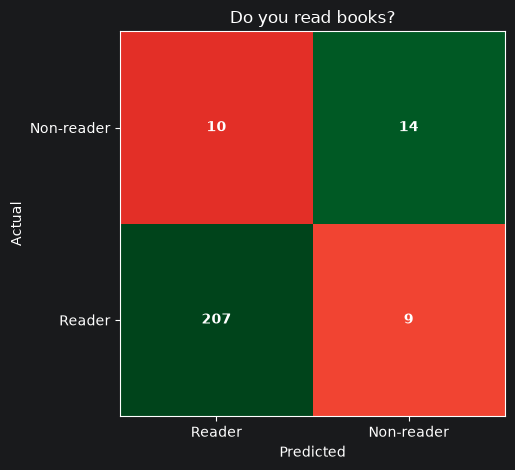

In [9]:
# TODO Assess the factors most responsible for determining a person's reading habits (PCA)
# TODO Determine the feasibility of a model for recommending books to a person according to their answers

def main():
    raw_data: pl.DataFrame = pl.read_csv("Lugeja25.tab", has_header=True, separator="\t")
    typed_data: tp.DataFrame[Answer] = tp.DataFrame(Answer, values=raw_data)
    # print(typed_data.head(1))

    is_reader_data = typed_data.transform(AnswerParts1_6WithQ1_V445)
    # find_best_params_for_catboost(is_reader_data)
    is_reader_predictions: tp.DataFrame[PredictedAndActualQ1] = predict_is_reader_parts_1_6(is_reader_data)
    visualize_is_reader_predictions(is_reader_predictions)

    #habits = predict_habits(typed_data)
    #visualize_predict_habits(habits)

if __name__ == "__main__":
    main()